In [1]:
import os
import shutil

SOURCE = "/content/drive/MyDrive/trendpulse/trendpulse/part2_numpy_pandas/data"

DESTINATION = "/content/drive/MyDrive/trendpulse/trendpulse/part3_visualization_eda/data"

os.makedirs(DESTINATION, exist_ok=True)

files = [
    "Copy of USvideos.csv",
    "Copy of GBvideos.csv",
    "Copy of INvideos.csv",
    "Copy of categories.csv"
]

for file in files:
    shutil.copy2(
        os.path.join(SOURCE, file),
        os.path.join(DESTINATION, file)
    )
    print("Copied:", file)

print("All datasets copied successfully!")

Copied: Copy of USvideos.csv
Copied: Copy of GBvideos.csv
Copied: Copy of INvideos.csv
Copied: Copy of categories.csv
All datasets copied successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

DATA_PATH = "/content/drive/MyDrive/trendpulse/trendpulse/part3_visualization_eda/data"

print("Libraries imported successfully!")
print("Data folder exists:", os.path.exists(DATA_PATH))

Libraries imported successfully!
Data folder exists: True


##Load and combine datasets

In [4]:
us = pd.read_csv(os.path.join(DATA_PATH, "Copy of USvideos.csv"))
gb = pd.read_csv(os.path.join(DATA_PATH, "Copy of GBvideos.csv"))
india = pd.read_csv(os.path.join(DATA_PATH, "Copy of INvideos.csv"))

# Add country column
us["country"] = "US"
gb["country"] = "GB"
india["country"] = "IN"

# Combine all datasets
df = pd.concat([us, gb, india], ignore_index=True)

print("Combined dataset shape:", df.shape)
print("\nCountry-wise records:")
print(df["country"].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Combined dataset shape: (46230, 17)

Country-wise records:
country
US    16080
GB    15075
IN    15075
Name: count, dtype: int64

First 5 rows:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,g_N-w8LeAi8,17.14.11,Honest Football Prank LEAKED,QuietSpeech10,22,2017-11-14T07:04:28.000Z,Monsoon|Robots,48555,2189.0,180,136.0,https://i.ytimg.com/vi/g_N-w8LeAi8/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
1,Ugyql2NlPAd,17.14.11,Surprising Cricket Review,IncredibleChallenge41,25,2017-11-12T22:35:48.000Z,Winter,198385,1159.0,492,1446.0,https://i.ytimg.com/vi/Ugyql2NlPAd/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
2,8fE19jkxJ9n,17.14.11,Mira Solis - Football (Live) OFFICIAL,WildTutorial42,10,2017-11-13T08:40:22.000Z,Cricket,231656,8742.0,896,432.0,https://i.ytimg.com/vi/8fE19jkxJ9n/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
3,WOY0nn7HCsO,17.14.11,Zed Rivera - Space (Lyric Video)?!,ShockingInterview30,10,2017-10-27T22:21:47.000Z,Festival|Guitar,8083,176.0,8,19.0,https://i.ytimg.com/vi/WOY0nn7HCsO/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
4,2Lc_Cs5VVr_,17.14.11,Surprising Election Recipe,UltimateVlog96,27,2017-11-09T13:20:20.000Z,Festival,373161,11305.0,167,891.0,https://i.ytimg.com/vi/2Lc_Cs5VVr_/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US


##Data profiling and missing-value analysis

In [7]:

# 1. Dataset dimensions

print("Dataset Shape:", df.shape)

# 2. Column data types

print("\nColumn Data Types:")
print(df.dtypes)

# 3. Missing value analysis

missing_analysis = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df)
    ) * 100
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage",
    ascending=False
)

print("\nMissing Value Analysis:")
display(missing_analysis)

# 4. Total missing values

print("\nTotal Missing Values:", df.isnull().sum().sum())

# 5. Duplicate analysis

print("\nDuplicate Rows:", df.duplicated().sum())

print(
    "Duplicate Video Records:",
    df.duplicated(subset=["video_id", "trending_date", "country"]).sum()
)

# 6. Numerical summary

print("\nNumerical Summary:")
display(df.describe())

# 7. Categorical summary

print("\nCategorical Summary:")
display(df.describe(include="object"))

# 8. Unique values

print("\nUnique Values Per Column:")
print(df.nunique())

# 9. Category dataset structure

print("\nCategory Dataset Columns:")
print(categories.columns.tolist())

print("\nCategory Dataset Sample:")
display(categories.head())

print("\nSECTION 2 COMPLETED!")

Dataset Shape: (46230, 17)

Column Data Types:
video_id                   object
trending_date              object
title                      object
channel_title              object
category_id                 int64
publish_time               object
tags                       object
views                       int64
likes                     float64
dislikes                    int64
comment_count             float64
thumbnail_link             object
comments_disabled            bool
ratings_disabled             bool
video_error_or_removed       bool
description                object
country                    object
dtype: object

Missing Value Analysis:


,Missing Count,Missing Percentage
description,1624,3.512870
comment_count,36,0.077872
likes,12,0.025957
video_id,0,0.000000
trending_date,0,0.000000
category_id,0,0.000000
publish_time,0,0.000000
channel_title,0,0.000000
title,0,0.000000
views,0,0.000000



Total Missing Values: 1672

Duplicate Rows: 230
Duplicate Video Records: 230

Numerical Summary:


,category_id,views,likes,dislikes,comment_count
count,46230.000000,4.623000e+04,4.621800e+04,46230.000000,46194.000000
mean,18.645339,1.178603e+06,4.580005e+04,2325.983625,3449.773347
std,7.646745,5.916188e+06,2.969554e+05,10518.962756,13665.153495
min,1.000000,1.066000e+03,0.000000e+00,0.000000,0.000000
25%,10.000000,1.294632e+05,3.656000e+03,213.000000,404.000000
50%,22.000000,3.182775e+05,1.020100e+04,594.000000,1074.000000
75%,24.000000,8.240505e+05,2.898775e+04,1666.000000,2779.000000
max,28.000000,3.607602e+08,2.753782e+07,618175.000000,778390.000000



Categorical Summary:


,video_id,trending_date,title,channel_title,publish_time,tags,thumbnail_link,description,country
count,46230,46230,46230,46230,46230,46230,46230,44606,46230
unique,14699,80,10404,438,14678,6056,14699,18,3
top,iAvRHGeUpBR,17.30.12,Sunny Park - Bangalore (Live),QuietChallenge75,2017-11-27T11:50:56.000Z,[none],https://i.ytimg.com/vi/iAvRHGeUpBR/default.jpg,Watch this video. Subscribe for more content a...,US
freq,28,608,66,2464,28,3785,28,2612,16080



Unique Values Per Column:
video_id                  14699
trending_date                80
title                     10404
channel_title               438
category_id                  14
publish_time              14678
tags                       6056
views                     45018
likes                     27949
dislikes                   7796
comment_count              9788
thumbnail_link            14699
comments_disabled             2
ratings_disabled              2
video_error_or_removed        2
description                  18
country                       3
dtype: int64

Category Dataset Columns:


NameError: name 'categories' is not defined

In [8]:
categories = pd.read_csv(
    os.path.join(DATA_PATH, "Copy of categories.csv")
)

print("Category columns:")
print(categories.columns.tolist())

print("\nCategory dataset:")
display(categories.head())

Category columns:
['category_id', 'category_name']

Category dataset:


,category_id,category_name
0,1,Film & Animation
1,2,Autos & Vehicles
2,10,Music
3,15,Pets & Animals
4,17,Sports


##Data cleaning and feature engineering

In [9]:
# ==========================================
# SECTION 3: DATA CLEANING
# ==========================================

# 1. Remove duplicate records

print("Before removing duplicates:", df.shape)

df = df.drop_duplicates(
    subset=["video_id", "trending_date", "country"]
)

print("After removing duplicates:", df.shape)


# 2. Handle missing values

# Fill missing likes and comments with 0
df["likes"] = df["likes"].fillna(0)
df["comment_count"] = df["comment_count"].fillna(0)

# Fill missing descriptions with empty text
df["description"] = df["description"].fillna("")


# 3. Convert date columns

df["trending_date"] = pd.to_datetime(
    df["trending_date"],
    format="%y.%d.%m",
    errors="coerce"
)

df["publish_time"] = pd.to_datetime(
    df["publish_time"],
    errors="coerce",
    utc=True
)


# 4. Merge category names

df = df.merge(
    categories,
    on="category_id",
    how="left"
)


# 5. Create days_to_trend feature

df["days_to_trend"] = (
    df["trending_date"].dt.date -
    df["publish_time"].dt.date
).apply(lambda x: x.days if pd.notna(x) else np.nan)


# 6. Remove invalid dates and negative time differences

df = df.dropna(
    subset=["trending_date", "publish_time", "category_name"]
)

df = df[df["days_to_trend"] >= 0].copy()


# 7. Display cleaned dataset

print("\nCleaned Dataset Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nRemaining Duplicates:", df.duplicated(
    subset=["video_id", "trending_date", "country"]
).sum())

print("\nFirst 5 Cleaned Records:")
display(df.head())

print("\nCategory Names:")
print(df["category_name"].value_counts())

print("\nSECTION 3 COMPLETED!")

Before removing duplicates: (46230, 17)
After removing duplicates: (46000, 17)

Cleaned Dataset Shape: (46000, 19)

Remaining Missing Values:
video_id                  0
trending_date             0
title                     0
channel_title             0
category_id               0
publish_time              0
tags                      0
views                     0
likes                     0
dislikes                  0
comment_count             0
thumbnail_link            0
comments_disabled         0
ratings_disabled          0
video_error_or_removed    0
description               0
country                   0
category_name             0
days_to_trend             0
dtype: int64

Remaining Duplicates: 0

First 5 Cleaned Records:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,category_name,days_to_trend
0,g_N-w8LeAi8,2017-11-14,Honest Football Prank LEAKED,QuietSpeech10,22,2017-11-14 07:04:28+00:00,Monsoon|Robots,48555,2189.0,180,136.0,https://i.ytimg.com/vi/g_N-w8LeAi8/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,People & Blogs,0
1,Ugyql2NlPAd,2017-11-14,Surprising Cricket Review,IncredibleChallenge41,25,2017-11-12 22:35:48+00:00,Winter,198385,1159.0,492,1446.0,https://i.ytimg.com/vi/Ugyql2NlPAd/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,News & Politics,2
2,8fE19jkxJ9n,2017-11-14,Mira Solis - Football (Live) OFFICIAL,WildTutorial42,10,2017-11-13 08:40:22+00:00,Cricket,231656,8742.0,896,432.0,https://i.ytimg.com/vi/8fE19jkxJ9n/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Music,1
3,WOY0nn7HCsO,2017-11-14,Zed Rivera - Space (Lyric Video)?!,ShockingInterview30,10,2017-10-27 22:21:47+00:00,Festival|Guitar,8083,176.0,8,19.0,https://i.ytimg.com/vi/WOY0nn7HCsO/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Music,18
4,2Lc_Cs5VVr_,2017-11-14,Surprising Election Recipe,UltimateVlog96,27,2017-11-09 13:20:20+00:00,Festival,373161,11305.0,167,891.0,https://i.ytimg.com/vi/2Lc_Cs5VVr_/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Education,5



Category Names:
category_name
Entertainment           12270
Music                   10310
People & Blogs           3804
Comedy                   3258
News & Politics          2422
Film & Animation         2297
Gaming                   2057
Sports                   1921
Howto & Style            1825
Education                1645
Science & Technology     1562
Autos & Vehicles         1007
Pets & Animals            913
Travel & Events           709
Name: count, dtype: int64

SECTION 3 COMPLETED!


##Statistical analysis and outlier detection

In [10]:
# ==========================================
# SECTION 4: STATISTICAL ANALYSIS
# ==========================================

# 1. Calculate mean, median and mode

for column in ["views", "likes"]:

    mean_value = df[column].mean()
    median_value = df[column].median()
    mode_value = df[column].mode()[0]

    print("\n", "=" * 40)
    print("STATISTICS FOR:", column.upper())
    print("=" * 40)

    print("Mean:", round(mean_value, 2))
    print("Median:", round(median_value, 2))
    print("Mode:", mode_value)

    # Determine distribution shape
    if mean_value > median_value:
        print("Distribution: Right-skewed")

    elif mean_value < median_value:
        print("Distribution: Left-skewed")

    else:
        print("Distribution: Approximately symmetric")


# 2. IQR outlier detection

outlier_results = []

for column in ["views", "likes"]:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_count = len(outliers)

    outlier_results.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

    print("\nOutlier Analysis:", column.upper())
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", outlier_count)


# 3. Display outlier summary

outlier_summary = pd.DataFrame(outlier_results)

print("\nFinal Outlier Summary:")
display(outlier_summary)

print("\nOutlier Decision:")
print(
    "Keep the outliers because unusually high views and likes "
    "may represent genuine viral videos. Removing them could "
    "hide important trending behaviour."
)

print("\nSECTION 4 COMPLETED!")


STATISTICS FOR: VIEWS
Mean: 1179665.24
Median: 318389.0
Mode: 16000
Distribution: Right-skewed

STATISTICS FOR: LIKES
Mean: 45838.71
Median: 10204.0
Mode: 0.0
Distribution: Right-skewed

Outlier Analysis: VIEWS
Q1: 129453.75
Q3: 824049.5
IQR: 694595.75
Lower Bound: -912439.875
Upper Bound: 1865943.125
Outlier Count: 5079

Outlier Analysis: LIKES
Q1: 3650.0
Q3: 28980.0
IQR: 25330.0
Lower Bound: -34345.0
Upper Bound: 66975.0
Outlier Count: 5263

Final Outlier Summary:


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,views,129453.75,824049.5,694595.75,-912439.875,1865943.125,5079
1,likes,3650.00,28980.0,25330.00,-34345.000,66975.000,5263



Outlier Decision:
Keep the outliers because unusually high views and likes may represent genuine viral videos. Removing them could hide important trending behaviour.

SECTION 4 COMPLETED!


##Correlation analysis and heatmap

Correlation Matrix:


,views,likes,dislikes,comment_count,days_to_trend
views,1.000000,0.920913,0.888529,0.915547,0.196053
likes,0.920913,1.000000,0.867614,0.812503,0.160313
dislikes,0.888529,0.867614,1.000000,0.888491,0.196454
comment_count,0.915547,0.812503,0.888491,1.000000,0.207558
days_to_trend,0.196053,0.160313,0.196454,0.207558,1.000000


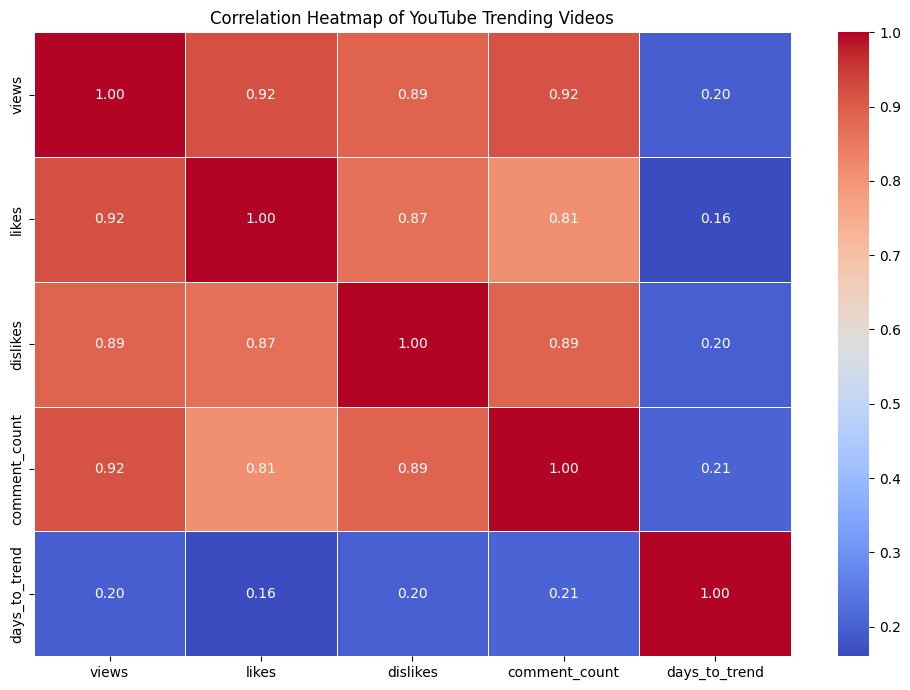


Two Strongest Correlations:
views  likes            0.920913
       comment_count    0.915547
dtype: float64

SECTION 5 COMPLETED!


In [14]:
# ==========================================
# SECTION 5: CORRELATION ANALYSIS
# ==========================================

# Select numerical columns

numeric_columns = [
    "views",
    "likes",
    "dislikes",
    "comment_count",
    "days_to_trend"
]

# Calculate correlation matrix

correlation_matrix = df[numeric_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)

# Create correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of YouTube Trending Videos")
plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "correlation_heatmap.png"),
    dpi=300
)

plt.show()


# Find the two strongest absolute correlations

correlation_pairs = correlation_matrix.abs().where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
).stack().sort_values(ascending=False)

print("\nTwo Strongest Correlations:")

print(correlation_pairs.head(2))

print("\nSECTION 5 COMPLETED!")

In [13]:
import os

BASE_PATH = "/content/drive/MyDrive/trendpulse/trendpulse/part3_visualization_eda"

CHART_PATH = os.path.join(BASE_PATH, "charts")

os.makedirs(CHART_PATH, exist_ok=True)

print("Chart folder ready:", CHART_PATH)

Chart folder ready: /content/drive/MyDrive/trendpulse/trendpulse/part3_visualization_eda/charts


##Matplotlib Visualization

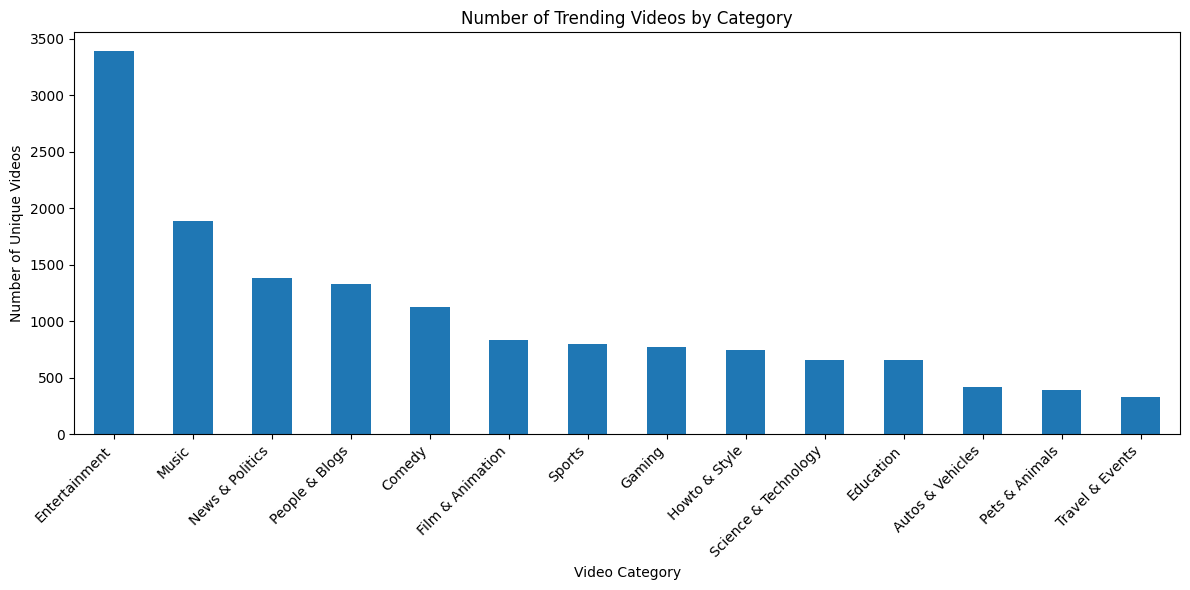

Category Distribution:


,video_id
category_name,
Entertainment,3387
Music,1883
News & Politics,1381
People & Blogs,1331
Comedy,1129
Film & Animation,829
Sports,797
Gaming,767
Howto & Style,743


In [15]:
# Count videos in each category

category_counts = (
    df.groupby("category_name")["video_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Create bar chart

plt.figure(figsize=(12, 6))

category_counts.plot(kind="bar")

plt.title("Number of Trending Videos by Category")
plt.xlabel("Video Category")
plt.ylabel("Number of Unique Videos")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "01_category_distribution.png"),
    dpi=300
)

plt.show()

print("Category Distribution:")
display(category_counts)

##Distribution of Views

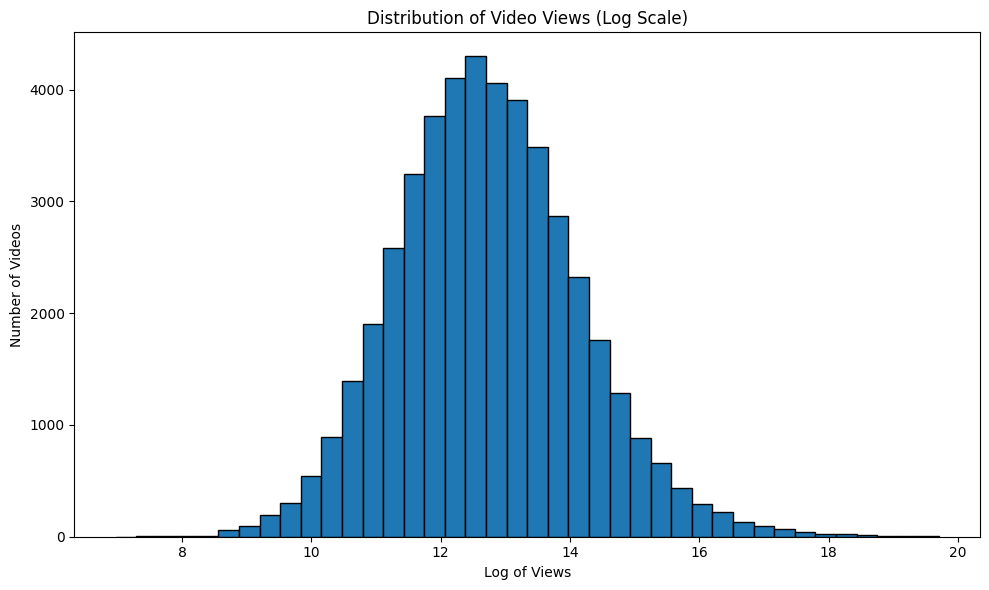

In [17]:
# Create log-transformed views
log_views = np.log1p(df["views"])

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(log_views, bins=40, edgecolor="black")

plt.title("Distribution of Video Views (Log Scale)")
plt.xlabel("Log of Views")
plt.ylabel("Number of Videos")

plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "02_views_distribution.png"),
    dpi=300
)

plt.show()

##Views vs Likes

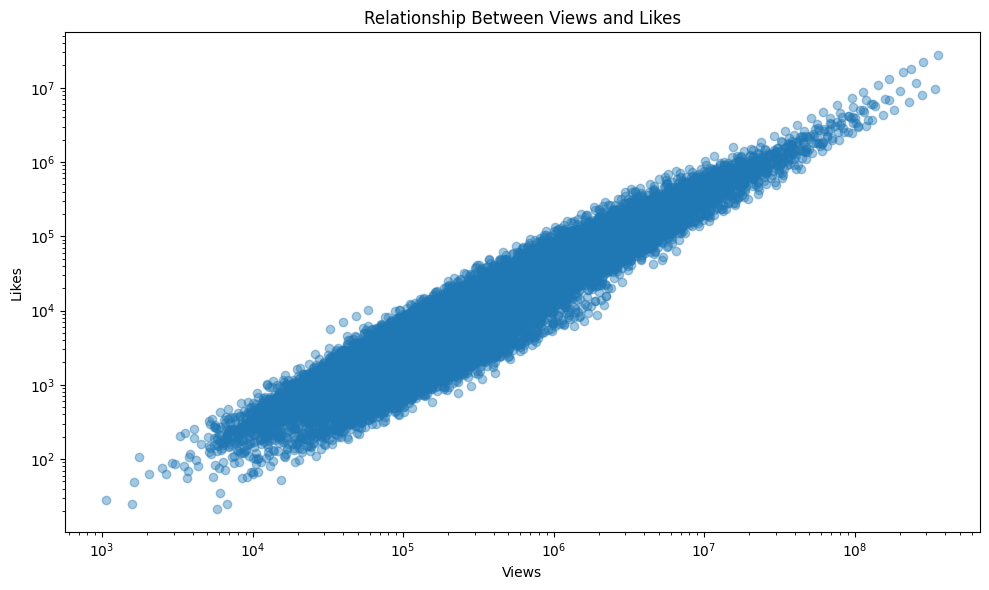

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["views"],
    df["likes"],
    alpha=0.4
)

plt.title("Relationship Between Views and Likes")
plt.xlabel("Views")
plt.ylabel("Likes")

plt.xscale("log")
plt.yscale("log")

plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "03_views_vs_likes.png"),
    dpi=300
)

plt.show()

##Trending Videos Over Time

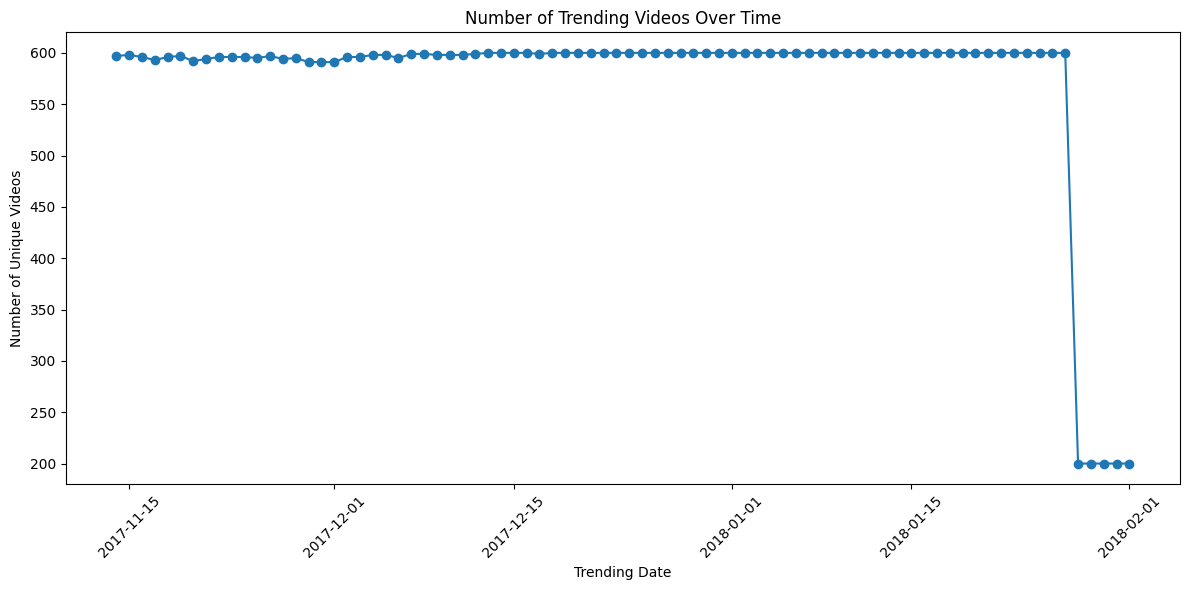

In [19]:
daily_trends = (
    df.groupby("trending_date")["video_id"]
    .nunique()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(daily_trends.index, daily_trends.values, marker="o")

plt.title("Number of Trending Videos Over Time")
plt.xlabel("Trending Date")
plt.ylabel("Number of Unique Videos")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "04_trending_over_time.png"),
    dpi=300
)

plt.show()

##Views by Category

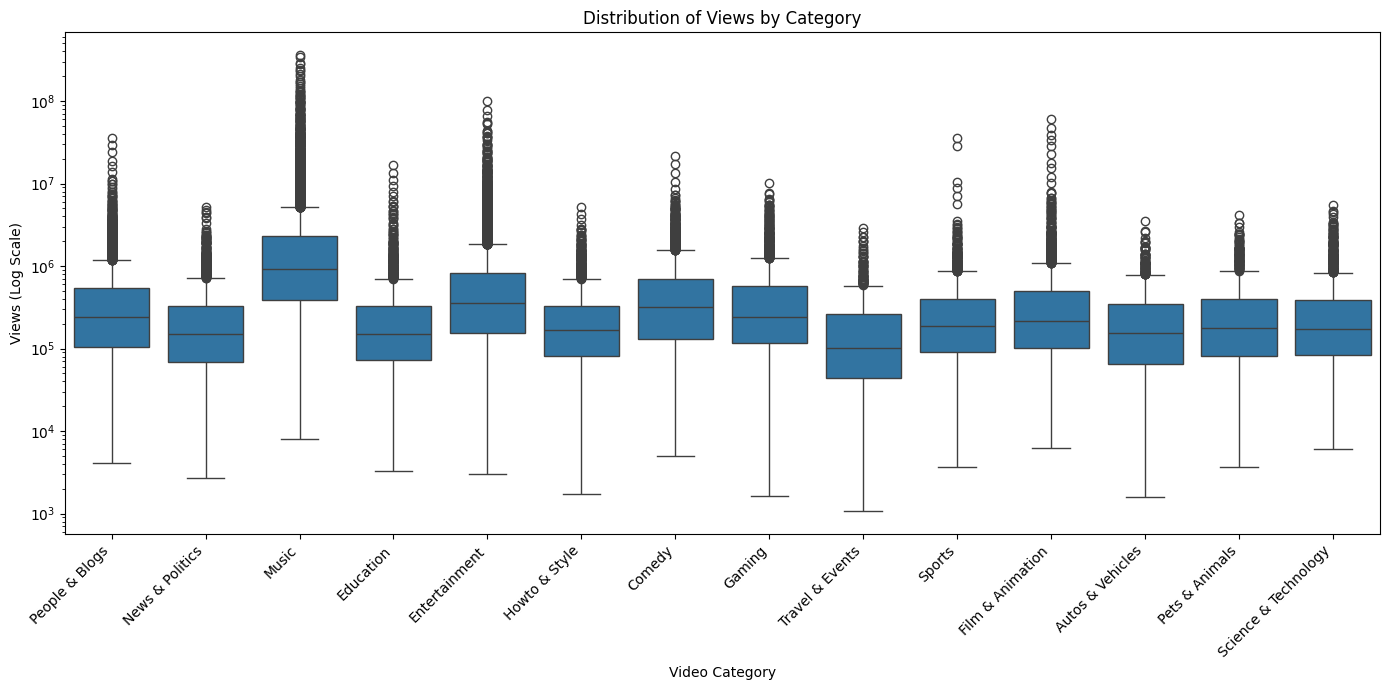

In [20]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="category_name",
    y="views"
)

plt.yscale("log")

plt.title("Distribution of Views by Category")
plt.xlabel("Video Category")
plt.ylabel("Views (Log Scale)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "05_views_by_category.png"),
    dpi=300
)

plt.show()

##Plotly Interactive Chart 1 of 2

In [21]:
plot_df = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

fig = px.scatter(
    plot_df,
    x="views",
    y="likes",
    color="category_name",
    hover_name="title",
    log_x=True,
    log_y=True,
    title="Interactive Relationship Between Views and Likes",
    labels={
        "views": "Views",
        "likes": "Likes",
        "category_name": "Category"
    }
)

fig.show()

fig.write_html(
    os.path.join(CHART_PATH, "06_interactive_views_likes.html")
)

##Average Views by Category and Country

In [22]:
avg_views = (
    df.groupby(["category_name", "country"])["views"]
    .mean()
    .reset_index()
)

fig = px.bar(
    avg_views,
    x="category_name",
    y="views",
    color="country",
    barmode="group",
    title="Average Video Views by Category Across Countries",
    labels={
        "category_name": "Video Category",
        "views": "Average Views",
        "country": "Country"
    }
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

fig.write_html(
    os.path.join(CHART_PATH, "07_interactive_category_country.html")
)

The interactive bar chart compares average video views across categories in the US, GB, and India. It helps identify categories that receive higher average views in each country. A grouped bar chart is suitable because it makes comparisons between multiple countries and categories easier.


##Funnel Analysis

In [23]:
# Create one record per unique video

video_summary = (
    df.groupby("video_id")
    .agg(
        peak_views=("views", "max"),
        peak_comments=("comment_count", "max"),
        category_name=("category_name", "first"),
        country=("country", "first")
    )
    .reset_index()
)

print("Total unique videos:", len(video_summary))

display(video_summary.head())

Total unique videos: 14699


,video_id,peak_views,peak_comments,category_name,country
0,--UQXlrk5E0,179541,658.0,Film & Animation,GB
1,--j83Wp5WrQ,68090,288.0,Entertainment,US
2,--pb5oKkYrH,582515,767.0,Music,GB
3,-0B4eg2Srpi,396797,1072.0,Entertainment,IN
4,-0dHuLKRPYS,198202,662.0,Sports,US


##Funnel Analysis

In [24]:
# Calculate funnel thresholds

median_views = video_summary["peak_views"].median()
percentile_90 = video_summary["peak_views"].quantile(0.90)

# Funnel stages

stage1 = len(video_summary)

stage2 = (video_summary["peak_views"] > median_views).sum()

stage3 = (video_summary["peak_views"] > percentile_90).sum()

stage4 = (video_summary["peak_comments"] >= 1000).sum()

# Create funnel table

funnel = pd.DataFrame({
    "Stage": [
        "All videos that trended",
        "Above median peak views",
        "Above 90th percentile peak views",
        "Videos with 1000+ comments"
    ],
    "Video Count": [
        stage1,
        stage2,
        stage3,
        stage4
    ]
})

funnel["Conversion Rate (%)"] = (
    funnel["Video Count"] / funnel["Video Count"].shift(1) * 100
)

funnel.loc[0, "Conversion Rate (%)"] = 100

display(funnel)

print("Median peak views:", median_views)
print("90th percentile peak views:", percentile_90)

,Stage,Video Count,Conversion Rate (%)
0,All videos that trended,14699,100.000000
1,Above median peak views,7349,49.996598
2,Above 90th percentile peak views,1470,20.002721
3,Videos with 1000+ comments,7157,486.870748


Median peak views: 265283.0
90th percentile peak views: 1646639.6


In [25]:
# Stage 4: Among videos above the 90th percentile,
# count those with at least 1000 comments

stage4 = (
    (video_summary["peak_views"] > percentile_90) &
    (video_summary["peak_comments"] >= 1000)
).sum()

# Rebuild funnel

funnel = pd.DataFrame({
    "Stage": [
        "All videos that trended",
        "Above median peak views",
        "Above 90th percentile peak views",
        "Videos with 1000+ comments"
    ],
    "Video Count": [
        stage1,
        stage2,
        stage3,
        stage4
    ]
})

funnel["Conversion Rate (%)"] = (
    funnel["Video Count"] /
    funnel["Video Count"].shift(1) * 100
)

funnel.loc[0, "Conversion Rate (%)"] = 100

display(funnel)

,Stage,Video Count,Conversion Rate (%)
0,All videos that trended,14699,100.000000
1,Above median peak views,7349,49.996598
2,Above 90th percentile peak views,1470,20.002721
3,Videos with 1000+ comments,1441,98.027211


##Retention Analysis

In [26]:
# Find each video's first trending date

first_dates = (
    df.groupby("video_id")["trending_date"]
    .min()
)

# Calculate trending day number

df["first_trending_date"] = df["video_id"].map(first_dates)

df["trend_day"] = (
    df["trending_date"] - df["first_trending_date"]
).dt.days + 1

# Calculate retention for days 1, 2, 3, 5 and 7

total_videos = df["video_id"].nunique()

retention_days = [1, 2, 3, 5, 7]

retention_results = []

for day in retention_days:

    active_videos = df.loc[
        df["trend_day"] == day,
        "video_id"
    ].nunique()

    percentage = active_videos / total_videos * 100

    retention_results.append({
        "Day": day,
        "Videos Still Trending": active_videos,
        "Retention (%)": percentage
    })

retention_df = pd.DataFrame(retention_results)

display(retention_df)

,Day,Videos Still Trending,Retention (%)
0,1,14699,100.000000
1,2,9259,62.990680
2,3,6158,41.894006
3,5,2880,19.593170
4,7,1479,10.061909


##Retention Curve

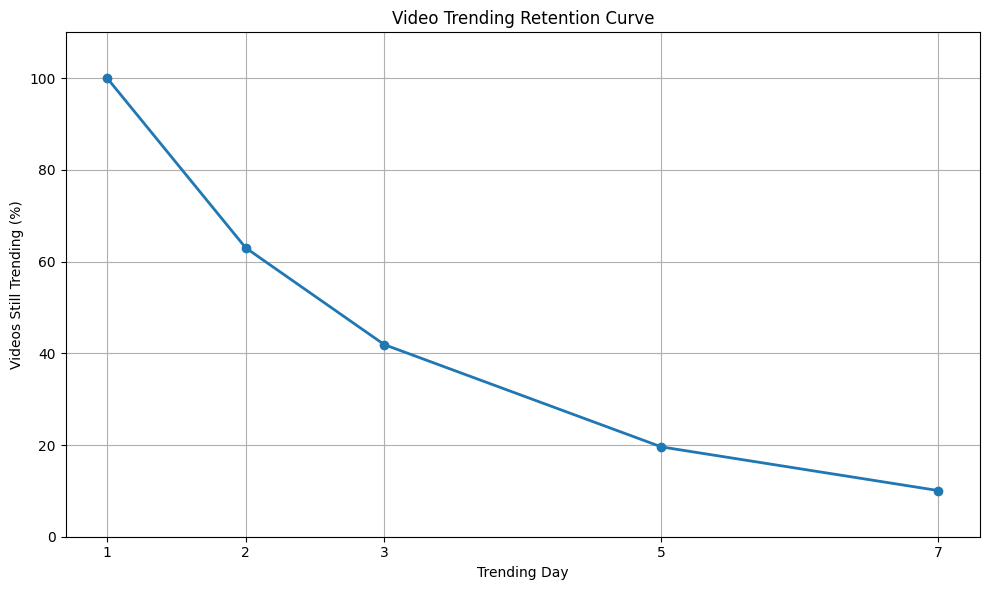

In [27]:
plt.figure(figsize=(10, 6))

plt.plot(
    retention_df["Day"],
    retention_df["Retention (%)"],
    marker="o",
    linewidth=2
)

plt.title("Video Trending Retention Curve")
plt.xlabel("Trending Day")
plt.ylabel("Videos Still Trending (%)")

plt.xticks([1, 2, 3, 5, 7])
plt.ylim(0, 110)
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "08_retention_curve.png"),
    dpi=300
)

plt.show()

##Compare Retention Across Countries

In [28]:
country_retention = []

for country in df["country"].unique():

    country_df = df[df["country"] == country]

    country_total = country_df["video_id"].nunique()

    for day in [1, 2, 3, 5, 7]:

        active = country_df.loc[
            country_df["trend_day"] == day,
            "video_id"
        ].nunique()

        percentage = active / country_total * 100

        country_retention.append({
            "Country": country,
            "Day": day,
            "Retention (%)": percentage
        })

country_retention_df = pd.DataFrame(country_retention)

display(
    country_retention_df.pivot(
        index="Day",
        columns="Country",
        values="Retention (%)"
    )
)

Country,GB,IN,US
Day,,,
1,97.009482,96.512419,99.684294
2,67.493314,54.763525,64.759274
3,48.285923,33.701939,43.567482
5,25.796256,13.695134,20.205209
7,14.369074,5.903368,10.812944


##Category-wise Retention

In [29]:
category_retention = []

for category in df["category_name"].unique():

    category_df = df[df["category_name"] == category]

    category_total = category_df["video_id"].nunique()

    for day in [1, 2, 3, 5, 7]:

        active = category_df.loc[
            category_df["trend_day"] == day,
            "video_id"
        ].nunique()

        percentage = active / category_total * 100

        category_retention.append({
            "Category": category,
            "Day": day,
            "Retention (%)": percentage
        })

category_retention_df = pd.DataFrame(category_retention)

display(
    category_retention_df.pivot(
        index="Category",
        columns="Day",
        values="Retention (%)"
    ).round(2)
)

Day,1,2,3,5,7
Category,,,,,
Autos & Vehicles,100.0,56.63,32.05,10.12,5.30
Comedy,100.0,65.37,42.16,17.27,7.26
Education,100.0,57.03,33.18,12.84,5.35
Entertainment,100.0,70.39,51.08,26.87,13.58
Film & Animation,100.0,60.92,40.29,15.68,7.24
Gaming,100.0,62.84,39.77,14.08,6.13
Howto & Style,100.0,58.14,33.51,12.11,4.04
Music,100.0,80.19,65.75,44.13,29.63
News & Politics,100.0,40.19,15.86,3.77,1.23


##Cohort Analysis

In [30]:
# Create video-level summary with first and last trending dates

cohort_data = (
    df.groupby("video_id")
    .agg(
        first_trending=("trending_date", "min"),
        last_trending=("trending_date", "max"),
        peak_views=("views", "max")
    )
    .reset_index()
)

# Calculate trending lifespan

cohort_data["lifespan_days"] = (
    cohort_data["last_trending"] -
    cohort_data["first_trending"]
).dt.days + 1

# Extract first trending month

cohort_data["cohort_month"] = (
    cohort_data["first_trending"].dt.to_period("M").astype(str)
)

display(cohort_data.head())

print("Total videos:", len(cohort_data))

,video_id,first_trending,last_trending,peak_views,lifespan_days,cohort_month
0,--UQXlrk5E0,2017-12-25,2017-12-28,179541,4,2017-12
1,--j83Wp5WrQ,2018-01-20,2018-01-21,68090,2,2018-01
2,--pb5oKkYrH,2017-12-04,2017-12-07,582515,4,2017-12
3,-0B4eg2Srpi,2018-01-20,2018-01-22,396797,3,2018-01
4,-0dHuLKRPYS,2018-01-27,2018-02-01,198202,6,2018-01


Total videos: 14699


Calculate monthly cohort metrics


In [31]:
cohort_summary = (
    cohort_data.groupby("cohort_month")
    .agg(
        video_count=("video_id", "nunique"),
        average_peak_views=("peak_views", "mean"),
        average_lifespan_days=("lifespan_days", "mean")
    )
    .reset_index()
)

display(cohort_summary.round(2))

,cohort_month,video_count,average_peak_views,average_lifespan_days
0,2017-11,3562,1105509.83,4.17
1,2017-12,5660,1042779.26,3.37
2,2018-01,5411,821974.74,2.88
3,2018-02,66,354867.68,1.00


Create the cohort chart

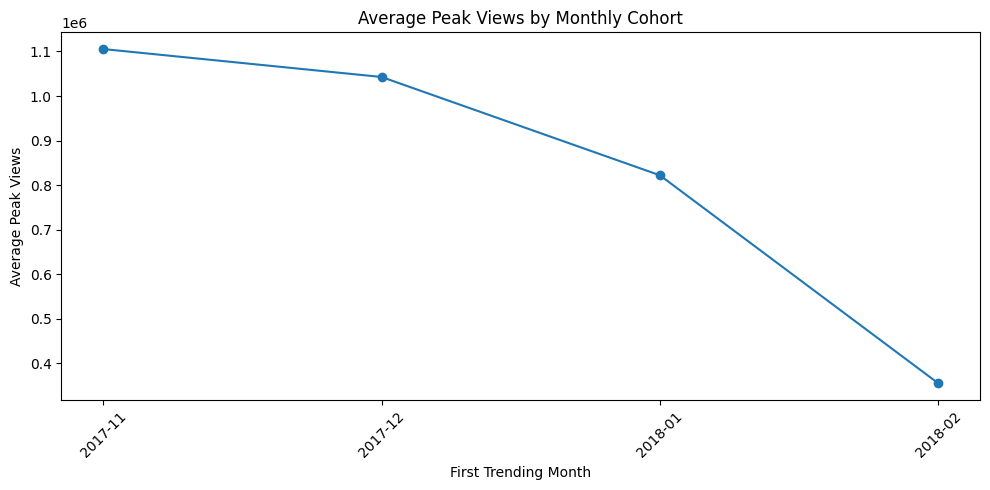

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    cohort_summary["cohort_month"],
    cohort_summary["average_peak_views"],
    marker="o"
)

plt.title("Average Peak Views by Monthly Cohort")
plt.xlabel("First Trending Month")
plt.ylabel("Average Peak Views")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(CHART_PATH, "09_cohort_analysis.png")
)

plt.show()

## Content Strategy Briefing

Entertainment was the most represented category, with 3,387 unique videos, followed by Music with 1,883 videos. However, Music showed the strongest audience retention, with 29.63% of its videos still trending on Day 7, compared with 13.58% for Entertainment. Overall, only 10.06% of videos remained trending on Day 7, indicating that most videos had a relatively short trending lifespan. Great Britain had the highest Day 7 retention at 14.37%, followed by the United States at 10.81% and India at 5.90%. The November 2017 cohort achieved the highest average peak views at approximately 1.11 million, while average views declined across the following cohorts. Content creators could explore Music and Entertainment content while focusing on strategies that encourage viewers to engage over several days. These findings are descriptive and are limited to the videos and observation period in the supplied dataset; they do not guarantee future performance.

In [33]:
# Create output folder
OUTPUT_PATH = os.path.join(BASE_PATH, "data")
os.makedirs(OUTPUT_PATH, exist_ok=True)

# 1. Save cleaned dataset
df.to_csv(
    os.path.join(OUTPUT_PATH, "part3_cleaned_dataset.csv"),
    index=False
)

# 2. Save video-level summary
video_summary.to_csv(
    os.path.join(OUTPUT_PATH, "video_summary.csv"),
    index=False
)

# 3. Save cohort analysis
cohort_summary.to_csv(
    os.path.join(OUTPUT_PATH, "cohort_summary.csv"),
    index=False
)

# 4. Save funnel analysis
funnel_summary = pd.DataFrame({
    "stage": [
        "All videos",
        "Above median peak views",
        "Above 90th percentile peak views",
        "Above 90th percentile with 1000+ comments"
    ],
    "video_count": [
        len(video_summary),
        int((video_summary["peak_views"] > video_summary["peak_views"].median()).sum()),
        int((video_summary["peak_views"] > video_summary["peak_views"].quantile(0.90)).sum()),
        int((
            (video_summary["peak_views"] > video_summary["peak_views"].quantile(0.90)) &
            (video_summary["peak_comments"] >= 1000)
        ).sum())
    ]
})

funnel_summary.to_csv(
    os.path.join(OUTPUT_PATH, "funnel_summary.csv"),
    index=False
)

print("Part 3 output files saved successfully!")

print("\nSaved files:")
print(os.listdir(OUTPUT_PATH))

Part 3 output files saved successfully!

Saved files:
['Copy of cleaned_video_records.csv', 'Copy of USvideos.csv', 'Copy of INvideos.csv', 'Copy of GBvideos.csv', 'Copy of categories.csv', 'Copy of combined_videos.csv', 'part3_cleaned_dataset.csv', 'video_summary.csv', 'cohort_summary.csv', 'funnel_summary.csv']


##Save retention analysis results

In [34]:
# Overall retention summary
retention_summary = pd.DataFrame({
    "day": [1, 2, 3, 5, 7],
    "retention_percentage": [100.00, 62.99, 41.89, 19.59, 10.06]
})

retention_summary.to_csv(
    os.path.join(OUTPUT_PATH, "retention_summary.csv"),
    index=False
)

# Country retention summary
country_retention.to_csv(
    os.path.join(OUTPUT_PATH, "country_retention_summary.csv"),
    index=False
)

# Category retention summary
category_retention.to_csv(
    os.path.join(OUTPUT_PATH, "category_retention_summary.csv"),
    index=False
)

print("Retention files saved successfully!")
print(os.listdir(OUTPUT_PATH))

AttributeError: 'list' object has no attribute 'to_csv'

In [36]:
print("Country retention type:", type(country_retention))
print("Category retention type:", type(category_retention))

print("\nCountry retention:")
print(country_retention)

print("\nCategory retention:")
print(category_retention)

Country retention type: <class 'list'>
Category retention type: <class 'list'>

Country retention:
[{'Country': 'US', 'Day': 1, 'Retention (%)': 99.68429360694554}, {'Country': 'US', 'Day': 2, 'Retention (%)': 64.75927387529597}, {'Country': 'US', 'Day': 3, 'Retention (%)': 43.56748224151539}, {'Country': 'US', 'Day': 5, 'Retention (%)': 20.2052091554854}, {'Country': 'US', 'Day': 7, 'Retention (%)': 10.812943962115233}, {'Country': 'GB', 'Day': 1, 'Retention (%)': 97.00948212983224}, {'Country': 'GB', 'Day': 2, 'Retention (%)': 67.4933138828106}, {'Country': 'GB', 'Day': 3, 'Retention (%)': 48.28592268417214}, {'Country': 'GB', 'Day': 5, 'Retention (%)': 25.79625577437394}, {'Country': 'GB', 'Day': 7, 'Retention (%)': 14.36907366885485}, {'Country': 'IN', 'Day': 1, 'Retention (%)': 96.51241919020075}, {'Country': 'IN', 'Day': 2, 'Retention (%)': 54.7635250085063}, {'Country': 'IN', 'Day': 3, 'Retention (%)': 33.701939435182034}, {'Country': 'IN', 'Day': 5, 'Retention (%)': 13.69513439

##Save retention results

In [37]:
# Convert lists into DataFrames
country_retention_df = pd.DataFrame(country_retention)
category_retention_df = pd.DataFrame(category_retention)

# Save country retention
country_retention_df.to_csv(
    os.path.join(OUTPUT_PATH, "country_retention_summary.csv"),
    index=False
)

# Save category retention
category_retention_df.to_csv(
    os.path.join(OUTPUT_PATH, "category_retention_summary.csv"),
    index=False
)

# Save overall retention
retention_summary.to_csv(
    os.path.join(OUTPUT_PATH, "retention_summary.csv"),
    index=False
)

print("All retention files saved successfully!")
print(os.listdir(OUTPUT_PATH))

All retention files saved successfully!
['Copy of cleaned_video_records.csv', 'Copy of USvideos.csv', 'Copy of INvideos.csv', 'Copy of GBvideos.csv', 'Copy of categories.csv', 'Copy of combined_videos.csv', 'part3_cleaned_dataset.csv', 'video_summary.csv', 'cohort_summary.csv', 'funnel_summary.csv', 'retention_summary.csv', 'country_retention_summary.csv', 'category_retention_summary.csv']


##README.md

In [38]:
readme_content = """
# TrendPulse — Part 3: Data Visualization & Exploratory Data Analysis

## Project Overview

TrendPulse analyzes YouTube trending video data from the United States,
Great Britain, and India.

Part 3 focuses on exploratory data analysis, statistical analysis,
data visualization, audience retention, funnel analysis, and cohort analysis.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Google Colab

## Dataset

The analysis combines YouTube trending video records from:
- United States (US)
- Great Britain (GB)
- India (IN)

The cleaned dataset contains 46,000 records and 14 categories.

## Analysis Performed

### 1. Data Cleaning
- Removed duplicate records.
- Handled missing values.
- Converted date columns.
- Merged category information.
- Calculated days_to_trend.

### 2. Statistical Analysis
- Calculated mean, median, and mode for views and likes.
- Identified right-skewed distributions.
- Used IQR to detect outliers.
- Kept outliers because viral videos are important to the analysis.

### 3. Visualizations
Created Matplotlib charts and interactive Plotly charts to explore:
- Category distribution.
- Views distribution.
- Views versus likes.
- Trending videos over time.
- Views by category.
- Correlation heatmap.
- Audience retention.
- Monthly cohort performance.

### 4. Correlation Analysis

Strongest correlations:
- Views and likes: 0.921
- Views and comment count: 0.916

These are strong positive relationships. Correlation does not imply causation.

### 5. Funnel Analysis

Total unique videos: 14,699

| Funnel Stage | Videos |
|---|---:|
| All videos | 14,699 |
| Above median peak views | 7,349 |
| Above 90th percentile peak views | 1,470 |
| Above 90th percentile with 1,000+ comments | 1,441 |

The largest drop-off occurred between all videos and videos above median peak views.

### 6. Audience Retention

| Day | Retention |
|---|---:|
| Day 1 | 100.00% |
| Day 2 | 62.99% |
| Day 3 | 41.89% |
| Day 5 | 19.59% |
| Day 7 | 10.06% |

Great Britain showed the highest Day 7 retention among the three countries.

Music had the strongest category retention at Day 7, with 29.63%.

### 7. Cohort Analysis

| Cohort | Videos | Average Peak Views | Average Lifespan |
|---|---:|---:|---:|
| 2017-11 | 3,562 | 1,105,509.83 | 4.17 days |
| 2017-12 | 5,660 | 1,042,779.26 | 3.37 days |
| 2018-01 | 5,411 | 821,974.74 | 2.88 days |
| 2018-02 | 66 | 354,867.68 | 1.00 day |

November 2017 had the highest average peak views and lifespan.

February's cohort contains only 66 videos, so its results should be interpreted cautiously.

## Content Strategy Briefing

Entertainment was the most represented category, with 3,387 unique videos, followed by Music with 1,883 videos. However, Music showed the strongest audience retention, with 29.63% of its videos still trending on Day 7, compared with 13.58% for Entertainment. Overall, only 10.06% of videos remained trending on Day 7. Great Britain had the highest Day 7 retention at 14.37%, followed by the United States at 10.81% and India at 5.90%. The November 2017 cohort achieved the highest average peak views at approximately 1.11 million. Content creators could explore Music and Entertainment content while focusing on strategies that encourage viewers to engage over several days.

## Project Limitations

- The analysis uses a historical dataset rather than live YouTube data.
- Only videos included in the supplied trending dataset were analyzed.
- Cohort sample sizes differ, especially in February 2018.
- Correlation does not establish causation.

## How to Run

1. Open the notebook in Google Colab.
2. Upload or connect the required dataset files.
3. Install the required libraries if needed:

   pip install pandas numpy matplotlib seaborn plotly

4. Run the notebook cells in order.

## Output Files

- part3_cleaned_dataset.csv
- video_summary.csv
- funnel_summary.csv
- retention_summary.csv
- country_retention_summary.csv
- category_retention_summary.csv
- cohort_summary.csv

Charts are stored in the charts folder.

---

Part 3 completed: Data Visualization & Exploratory Data Analysis.
"""

readme_path = os.path.join(BASE_PATH, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [39]:
# Check all Part 3 project files

for root, dirs, files in os.walk(BASE_PATH):
    level = root.replace(BASE_PATH, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in files:
        print(f"{indent}    {filename}")

part3_visualization_eda/
    README.md
    requirements.txt
    data/
        Copy of cleaned_video_records.csv
        Copy of USvideos.csv
        Copy of INvideos.csv
        Copy of GBvideos.csv
        Copy of categories.csv
        Copy of combined_videos.csv
        part3_cleaned_dataset.csv
        video_summary.csv
        cohort_summary.csv
        funnel_summary.csv
        retention_summary.csv
        country_retention_summary.csv
        category_retention_summary.csv
    notebooks/
    charts/
        correlation_heatmap.png
        01_category_distribution.png
        02_views_distribution.png
        03_views_vs_likes.png
        04_trending_over_time.png
        05_views_by_category.png
        06_interactive_views_likes.html
        07_interactive_category_country.html
        08_retention_curve.png
        09_cohort_analysis.png
